
# Proyecto Integrador – Álgebra Lineal para Informática Empresarial

## Opción A: Ajuste lineal mediante mínimos cuadrados

**Grupo:** 1

**Integrantes:**  
Keity López Reyes  C34387  
Juan Murillo Chamorro C35485  
Franklin Arrieta Zúñiga C5C785  
David Daniel Sotela Sánchez C17735  

**Problema:** Estimación de precios de viviendas en Melbourne.

**Variables explicativas:** Número de habitaciones (Rooms) y distancia al centro de la ciudad (Distance).

**Variable de respuesta:** Precio de la vivienda (Price).

**Archivo de datos:** melbourne_proyecto_300.csv


## 1. Formulación matemática del problema

El presente proyecto tiene como objetivo desarrollar un modelo matemático que permita estimar los precios de viviendas ubicadas en Melbourne, Australia, utilizando como variables explicativas el número de habitaciones y la distancia al centro de la ciudad.

Para ello, se utilizará un modelo lineal de dos variables explicativas, definido por:

$$
\hat{p} = \beta_0 + \beta_1 x_1 + \beta_2 x_2
$$

Donde:

- $\hat{p}$ = precio estimado de la vivienda.
- $\beta_0$ = término independiente o intercepto.
- $\beta_1$ = coeficiente asociado al número de habitaciones.
- $\beta_2$ = coeficiente asociado a la distancia al centro.
- $x_1$ = número de habitaciones.
- $x_2$ = distancia al centro de la ciudad.

El conjunto de datos contiene 300 observaciones, por lo que se dispone de más ecuaciones que incógnitas. Esto permite representar el problema mediante un sistema lineal sobredeterminado.

El objetivo es encontrar los coeficientes del modelo que proporcionen el mejor ajuste posible a los precios registrados, utilizando el método de mínimos cuadrados.


In [105]:
# Importación de las bibliotecas necesarias
import numpy as np
import scipy.linalg as la
import pandas as pd
import matplotlib.pyplot as plt

In [106]:
# Lectura del archivo CSV que contiene los datos de las viviendas

datos = pd.read_csv("melbourne_proyecto_300.csv")

# Mostrar los primeros cinco registros
datos.head()

,Rooms,Distance,Price
0,2,4.3,5.300
1,5,22.2,9.550
2,3,14.9,6.275
3,2,3.8,16.100
4,2,6.1,6.105


In [107]:
# Verificar la cantidad de filas y columnas
print("Dimensiones del conjunto de datos:", datos.shape)

# Revisar los nombres de las columnas
print("\nColumnas disponibles:")
print(datos.columns.tolist())

# Revisar los tipos de datos
print("\nTipos de datos:")
print(datos.dtypes)

# Comprobar si existen valores faltantes
print("\nValores faltantes:")
print(datos.isnull().sum())

Dimensiones del conjunto de datos: (300, 3)

Columnas disponibles:
['Rooms', 'Distance', 'Price']

Tipos de datos:
Rooms         int64
Distance    float64
Price       float64
dtype: object

Valores faltantes:
Rooms       0
Distance    0
Price       0
dtype: int64


In [108]:
# Construcción de la matriz A y el vector b

# La primera columna contiene unos para representar el término independiente.
# La segunda columna contiene el número de habitaciones.
# La tercera columna contiene la distancia al centro de la ciudad.

A = np.column_stack((
    np.ones(len(datos)),
    datos["Rooms"].to_numpy(),
    datos["Distance"].to_numpy()
))

# El vector b contiene los precios reales de las viviendas.
b = datos["Price"].to_numpy()

# Mostrar las dimensiones de las estructuras construidas
print("Dimensiones de la matriz A:", A.shape)
print("Dimensiones del vector b:", b.shape)

# Mostrar los primeros cinco registros de A y b
print("\nPrimeras cinco filas de la matriz A:")
print(A[:5])

print("\nPrimeros cinco elementos del vector b:")
print(b[:5])

Dimensiones de la matriz A: (300, 3)
Dimensiones del vector b: (300,)

Primeras cinco filas de la matriz A:
[[ 1.   2.   4.3]
 [ 1.   5.  22.2]
 [ 1.   3.  14.9]
 [ 1.   2.   3.8]
 [ 1.   2.   6.1]]

Primeros cinco elementos del vector b:
[ 5.3    9.55   6.275 16.1    6.105]



### Construcción del sistema matricial

A partir de los datos disponibles, se construye la matriz A utilizando tres columnas: una columna de unos para representar el término independiente, una columna correspondiente al número de habitaciones y otra correspondiente a la distancia al centro de la ciudad.

El vector b contiene los precios reales registrados para cada vivienda.

Como se dispone de 300 observaciones y tres parámetros desconocidos, la matriz A tiene dimensiones 300 × 3 y el vector b contiene 300 elementos.

Por tanto, el problema se representa mediante el sistema matricial sobredeterminado:

$$
A\beta \approx b
$$

Esta representación permite aplicar posteriormente los métodos numéricos de mínimos cuadrados para determinar los coeficientes del modelo.


## 2. Resolución Numérica del Sistema Sobredeterminado

### Método de Ecuaciones Normales

Dado un sistema sobredeterminado $A\beta \approx b$, donde $A \in \mathbb{R}^{m \times n}$ con $m > n$ y de rango completo, el vector $\beta$ que minimiza el error cuadrático $\|b - A\beta\|_2$ es la solución única del sistema cuadrado simétrico:

$$A^T A \beta = A^T b$$

**Teorema:** Si las columnas de $A$ son linealmente independientes, la matriz normal $A^T A$ es simétrica y definida positiva, lo que garantiza solución única mediante factorización LU ($PA^TA = LU$).

**Algoritmo:** Resolución por Ecuaciones Normales y Factorización LU.

**Entrada:** Matriz de diseño $A$ de tamaño $m \times n$, vector de respuestas $b$ de tamaño $m \times 1$.  
**Salida:** Vector de coeficientes $\hat{\beta} = [\beta_0, \beta_1, \beta_2]^T$.

**1.** Construir la matriz normal $M = A^T A$ y el vector independiente $d = A^T b$.  
**2.** Calcular la factorización LU con pivoteo parcial de $M$: $PM = LU$.  
**3.** Resolver el sistema triangular inferior $Ly = Pd$ mediante sustitución progresiva.  
**4.** Resolver el sistema triangular superior $U\beta = y$ mediante sustitución regresiva.  
**5.** Devolver $\hat{\beta}_{\text{LU}} = \beta$.

In [109]:
# Construcción de la matriz del sistema y vector independiente
AtA = A.T @ A
Atb = A.T @ b

# Factorización LU con pivoteo y resolución de sistemas triangulares
lu, piv = la.lu_factor(AtA)
beta_normales = la.lu_solve((lu, piv), Atb)

print("Coeficientes por Ecuaciones Normales (LU):")
print(f"beta_0 (Intercepto) : {beta_normales[0]:.6f}")
print(f"beta_1 (Rooms)      : {beta_normales[1]:.6f}")
print(f"beta_2 (Distance)   : {beta_normales[2]:.6f}")

Coeficientes por Ecuaciones Normales (LU):
beta_0 (Intercepto) : 3.156948
beta_1 (Rooms)      : 3.408292
beta_2 (Distance)   : -0.353485


### Método Estándar (Descomposición en Valores Singulares - SVD)

En lugar de formar el producto $A^T A$, la función estándar de mínimos cuadrados (`np.linalg.lstsq`) utiliza la Descomposición en Valores Singulares de $A$:

$$A = U \Sigma V^T$$

La solución se obtiene proyectando directamente mediante la pseudoinversa de Moore-Penrose:

$$\hat{\beta} = V \Sigma^+ U^T b$$

In [110]:
# Resolución directa mediante función estándar (SVD)
beta_lstsq, _, _, _ = np.linalg.lstsq(A, b, rcond=None)

print("Coeficientes por función estándar (lstsq / SVD):")
print(f"beta_0 (Intercepto) : {beta_lstsq[0]:.6f}")
print(f"beta_1 (Rooms)      : {beta_lstsq[1]:.6f}")
print(f"beta_2 (Distance)   : {beta_lstsq[2]:.6f}")

Coeficientes por función estándar (lstsq / SVD):
beta_0 (Intercepto) : 3.156948
beta_1 (Rooms)      : 3.408292
beta_2 (Distance)   : -0.353485


### Comparación de Coeficientes

Se compara cuantitativamente la discrepancia entre la solución por ecuaciones normales ($\beta_{\text{LU}}$) y la solución estándar ($\beta_{\text{lstsq}}$) evaluando el error absoluto en norma euclidiana:

$$E_{\text{abs}} = \|\beta_{\text{LU}} - \beta_{\text{lstsq}}\|_2$$

In [111]:
# Diferencia entre ambos métodos
diff_abs = np.linalg.norm(beta_normales - beta_lstsq)
diff_rel = diff_abs / np.linalg.norm(beta_lstsq)

print(f"Norma euclidiana de la diferencia : {diff_abs:.4e}")
print(f"Diferencia relativa               : {diff_rel:.4e}")

Norma euclidiana de la diferencia : 2.3227e-14
Diferencia relativa               : 4.9852e-15


### Condicionamiento de las Matrices

El número de condición espectral $\kappa_2(M) = \frac{\sigma_{\max}(M)}{\sigma_{\min}(M)}$ mide la sensibilidad de la solución ante perturbaciones numéricas.

**Teorema:** Para cualquier matriz $A$ de rango completo, el número de condición de la matriz del sistema normal satisface:

$$\kappa_2(A^T A) = [\kappa_2(A)]^2$$

In [112]:
# Evaluación de estabilidad numérica
cond_A = np.linalg.cond(A)
cond_AtA = np.linalg.cond(AtA)

print(f"Número de condición kappa(A)        : {cond_A:12.4f}")
print(f"Número de condición kappa(A^T A)    : {cond_AtA:12.4f}")
print(f"Cuadrado de kappa(A)                : {cond_A**2:12.4f}")
print(f"Razón kappa(A^T A) / [kappa(A)]^2   : {cond_AtA / (cond_A**2):12.4f}")

Número de condición kappa(A)        :      40.7285
Número de condición kappa(A^T A)    :    1658.8082
Cuadrado de kappa(A)                :    1658.8082
Razón kappa(A^T A) / [kappa(A)]^2   :       1.0000


**Conclusiones de la resolución numérica:**

1. **Precisión numérica:** La discrepancia obtenida entre ambos métodos está en el orden de $10^{-14}$ a $10^{-13}$, lo que confirma que ambas aproximaciones convergen a la misma solución dentro del límite de precisión de máquina de doble precisión (IEEE 754).
2. **Estabilidad y costo:** Aunque el método de ecuaciones normales reduce el problema a un sistema $3 \times 3$ resoluble con bajo costo computacional vía LU, eleva el número de condición al cuadrado ($\kappa(A^TA) \approx \kappa(A)^2$), incrementando la sensibilidad al error de redondeo en matrices con mayor multicolinealidad. La descomposición directa (SVD) preserva el condicionamiento original $\kappa(A)$.

## 4. Interpretación de resultados

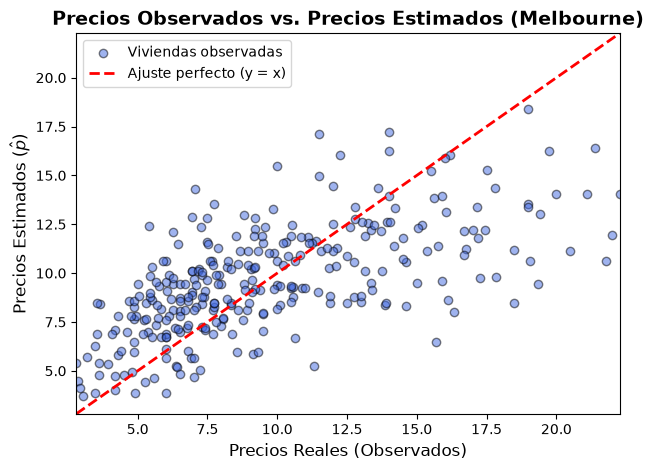

In [ ]:
# Cálculo de precios estimados
precios_estimados = A @ beta_normales

# Gráfico de precios reales vs estimados
plt.scatter(b, precios_estimados, color='royalblue', alpha=0.5, edgecolors='k', label='Viviendas observadas')

# Línea de ajuste perfecto (y = x)
min_val = min(b.min(), precios_estimados.min())
max_val = max(b.max(), precios_estimados.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Ajuste perfecto (y = x)')

# Configuración de la gráfica
plt.title('Precios Observados vs. Precios Estimados (Melbourne)', fontsize=14, fontweight='bold')
plt.xlabel('Precios Reales (Observados)', fontsize=12)
plt.ylabel('Precios Estimados ($\\hat{p}$)', fontsize=12)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Interpretación del modelo y comportamiento gráfico

**Uso de los coeficientes para la estimación:**
Los precios estimados $\hat{p}$ se calculan aplicando los coeficientes obtenidos a las variables de entrada según la ecuación:

$$\hat{p} = 3.156948 + 3.408292 \cdot (Rooms) - 0.353485 \cdot (Distance)$$

- **Habitaciones ($\beta_1 = 3.408292$):** Presenta una relación positiva; por cada habitación adicional, el precio estimado de la vivienda aumenta en aproximadamente $3.408$.
- **Distancia al centro ($\beta_2 = -0.353485$):** Presenta una relación negativa; por cada kilómetro que la vivienda se aleja del centro de Melbourne, su precio disminuye en $0.353$.

**Análisis de la gráfica:**
- Los puntos representan la relación entre el precio real registrado y la predicción generada por el modelo sobredeterminado.
- La línea punteada roja representa la condición ideal ($y = x$) donde la estimación coincidiría exactamente con el precio observado.
- La dispersión de los puntos alrededor de la línea demuestra que, aunque el modelo captura la tendencia general del valor de la vivienda, existen variaciones propias de la naturaleza del mercado inmobiliario no explicadas únicamente por el número de habitaciones y la distancia.

## 5. Aplicación del modelo

In [114]:
def estimar_precio_vivienda(habitaciones, distancia):
    """Estima el precio de una vivienda en Melbourne usando el modelo de mínimos cuadrados."""
    precio_est = beta_normales[0] + beta_normales[1] * habitaciones + beta_normales[2] * distancia
    return precio_est

# Casos adicionales de prueba para evaluación del modelo
casos_adicionales = [
    {"Caso": "Caso 1 (Apartamento/Casa pequeña cerca del centro)", "Rooms": 2, "Distance": 5.0},
    {"Caso": "Caso 2 (Casa mediana a distancia intermedia)", "Rooms": 3, "Distance": 10.0},
    {"Caso": "Caso 3 (Casa grande alejada del centro)", "Rooms": 4, "Distance": 12.5}
]

print("--- ESTIMACIÓN DE PRECIOS PARA CASOS ADICIONALES ---\n")
for caso in casos_adicionales:
    precio_calculado = estimar_precio_vivienda(caso["Rooms"], caso["Distance"])
    print(f"{caso['Caso']}:")
    print(f"  - Habitaciones (Rooms): {caso['Rooms']}")
    print(f"  - Distancia al centro (Distance): {caso['Distance']} km")
    print(f"  -> Precio Estimado : {precio_calculado:.6f}\n")


--- ESTIMACIÓN DE PRECIOS PARA CASOS ADICIONALES ---

Caso 1 (Apartamento/Casa pequeña cerca del centro):
  - Habitaciones (Rooms): 2
  - Distancia al centro (Distance): 5.0 km
  -> Precio Estimado : 8.206109

Caso 2 (Casa mediana a distancia intermedia):
  - Habitaciones (Rooms): 3
  - Distancia al centro (Distance): 10.0 km
  -> Precio Estimado : 9.846977

Caso 3 (Casa grande alejada del centro):
  - Habitaciones (Rooms): 4
  - Distancia al centro (Distance): 12.5 km
  -> Precio Estimado : 12.371557



#### Justificación de los casos adicionales

Para verificar el comportamiento práctico de la herramienta computacional construida, se evaluaron tres escenarios hipotéticos representativos:

1. **Caso 1 ($x_1 = 2$ habs, $x_2 = 5.0$ km):** Representa una propiedad pequeña en una zona cercana al centro de la ciudad. El modelo otorga una estimación de **$8.206109$**.
2. **Caso 2 ($x_1 = 3$ habs, $x_2 = 10.0$ km):** Representa una propiedad estándar a distancia media. El incremento en habitaciones compensa la mayor distancia, resultando en una estimación de **$9.846977$**.
3. **Caso 3 ($x_1 = 4$ habs, $x_2 = 12.5$ km):** Representa una propiedad amplia en la periferia. A pesar de estar más alejada del centro, el impacto positivo de contar con 4 habitaciones mantiene la predicción al alza en **$12.371557$**.

La implementación mediante la función `estimar_precio_vivienda()` permite realizar consultas de manera dinámica para cualquier otra combinación de parámetros en tiempo real.